## **Langchain Version V1**

LangChain is an open source orchestration framework for application development using large language models (LLMs). Available in both Python- and Javascript-based libraries, LangChain’s tools and APIs simplify the process of building LLM-driven applications like chatbots and AI agents. 

LangChain serves as a generic interface for nearly any LLM, providing a centralized development environment to build LLM applications and integrate them with external data sources and software workflows. LangChain’s module-based approach allows developers and data scientists to dynamically compare different prompts and even different foundation models with minimal need to rewrite code. This modular environment also allows for programs that use multiple LLMs: for example, an application that uses one LLM to interpret user queries and another LLM to author a response.


#### Key Components and Ecosystem

- **Models & Prompts**: Provides unified interfaces to swap between LLMs (such as OpenAI, Google, AWS, and open-source models) along with prompt templates and output parsers.
- **Chains & Workflows**: Connects sequences of steps—such as retrieving data, prompting a model, and formatting output—using composable syntax like LangChain Expression Language (LCEL).
- **Retrieval (RAG)**: Connects document loaders, text splitters, and vector databases so models can answer questions using private or real-time data.
- **Agents & Memory**: Enables models to use external tools or APIs, maintain conversation history, and run stateful workflows via LangGraph.
- **Observability & Deployment**: Pairs with LangSmith for tracing, testing, evaluation, and monitoring across the agent development lifecycle.

#### Common Usage Examples

- **Knowledge-base chatbots**: Answering questions grounded in company documents or databases through Retrieval-Augmented Generation (RAG).
- **AI agents and assistants**: Automating multi-step tasks by calling APIs, searching the web, or interacting with software tools.
• **Document and code workflows**: Summarizing long texts, extracting structured data, and analyzing code.

#### Similar Frameworks and Alternatives

Because LangChain is a specific software framework rather than a standalone word, it does not have exact lexical synonyms. In AI development, developers often compare it with similar LLM orchestration and agent frameworks—such as **LlamaIndex (especially for data indexing and RAG), Semantic Kernel, Haystack, or custom SDKs** built directly on model APIs.

### Table of Contents

| S.No. | Topic |
|---|---|
| 1 | Agent Creation using `create_agent` |
| 2 | Model Integration using OpenAI, Gemini, and Groq API Keys |
| 3 | `ChatOpenAI`, `ChatGoogleGenerativeAI`, `ChatGroq` |
| 4 | Streaming |
| 5 | Batching |
| 6 | Tools |
| 7 | Tools Execution Loop |
| 8 | Messages - Text Prompt |
| 9 | Message Prompt - System Prompt, Human Prompt, AI Prompt, Tool Prompt |
| 10. | Conversation History |
| 11. | Structured Output - Pydantic (Message output alongside parsed structure, Nested Structure) |
| 11. | Structured Output - TypedDict |
| 12. | Structured Output - Dataclass |
| 13. | Middleware and uses |
| 14. | Middleware (Built-in) - Summarization Middleware|
| 15. | Middleware (Built-in) - Human in the Loop|

In [1]:
import langchain
langchain.__version__

'1.4.9'

In [ ]:
import os 
from dotenv import load_dotenv
load_dotenv()

os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

### Agents

LLM has Knowledge cutoff. Agent can make decisons and check what new data is available for answering user queries.

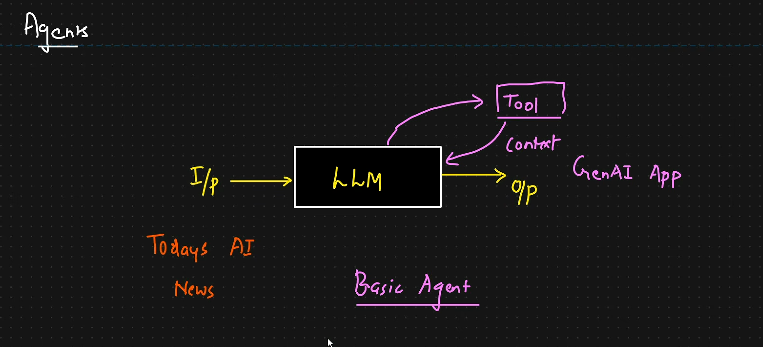



### Creating an Agent using Groq API and using OpenAI model

In [5]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

# llm = ChatGroq(model="qwen/qwen3.8-27b")

def get_weather(city:str)-> str:
    """Get the weather for a city."""
    return f"The weather in {city} is sunny."

llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0)

agent = create_agent(
    model=llm, # Notice: no quotes around llm
    tools=[get_weather],
    system_prompt="You are a helpful assistant."
)

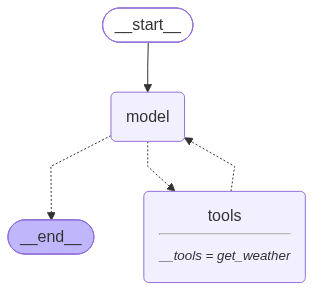

In [6]:
# Agent diagram after creating a weather tool
agent

In [7]:
response = agent.invoke({"messages":[{"role": "user", "content": "What is the weather of New Delhi?"}]})
response


{'messages': [HumanMessage(content='What is the weather of New Delhi?', additional_kwargs={}, response_metadata={}, id='ce7efc99-0f18-4145-98eb-8a1e06a6a0dc'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to call get_weather function with city "New Delhi".', 'tool_calls': [{'id': 'fc_77d3b6fc-3226-410a-9361-a4d01f2fb71a', 'function': {'arguments': '{"city":"New Delhi"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 137, 'total_tokens': 175, 'completion_time': 0.039032429, 'completion_tokens_details': {'reasoning_tokens': 14}, 'prompt_time': 0.006654498, 'prompt_tokens_details': None, 'queue_time': 0.374365348, 'total_time': 0.045686927}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_bb6a356524', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c64d-23dc-72f5-a381-f89257729851-0', tool_calls=[{'

In [8]:
response["messages"][-1].content

'The weather in New Delhi is sunny.'

In [9]:
agent.invoke({"messages": "What is the temperature in Visakapatnam?"})

{'messages': [HumanMessage(content='What is the temperature in Visakapatnam?', additional_kwargs={}, response_metadata={}, id='2584b32a-187c-4292-be10-6660d46c3742'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to call get_weather function with city "Visakapatnam".', 'tool_calls': [{'id': 'fc_1f27cc2f-0d7b-4e37-b80f-1805d5c01364', 'function': {'arguments': '{"city":"Visakapatnam"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 42, 'prompt_tokens': 139, 'total_tokens': 181, 'completion_time': 0.047211156, 'completion_tokens_details': {'reasoning_tokens': 16}, 'prompt_time': 0.009661778, 'prompt_tokens_details': None, 'queue_time': 0.285057303, 'total_time': 0.056872934}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_9b8528b477', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c64d-2ab7-74e5-bfa1-af6417508737-0', t

In [10]:
#### Another alternative of coding but this is not easy to me as of now as it uses some more libraries

# # import os
# from langchain_groq import ChatGroq
# from langchain_core.prompts import ChatPromptTemplate
# from langchain_core.tools import tool

# # Modern pure-LangChain agents must be imported from the classic package
# from langchain_classic.agents import AgentExecutor, create_tool_calling_agent

# # Initialize the Groq LLM instance
# # llm = ChatGroq(model="llama-3.1-8b-instant")
# llm = ChatGroq(model="openai/gpt-oss-20b")

# # Define the tool
# @tool
# def get_weather(city: str) -> str:
#     """Get the weather for a city."""
#     return f"The weather in {city} is sunny."

# tools = [get_weather]

# # Create the prompt (Tool calling agents require a scratchpad placeholder)
# prompt = ChatPromptTemplate.from_messages([
#     ("system", "You are a helpful assistant."),
#     ("human", "{input}"),
#     ("placeholder", "{agent_scratchpad}"),
# ])

# # Construct the pure LangChain agent
# agent = create_tool_calling_agent(llm, tools, prompt)

# # Create the executor which runs the reasoning loop
# agent_executor = AgentExecutor(agent=agent, tools=tools, verbose=True)

# # Invoke the agent
# response = agent_executor.invoke({
#     "input": "What is the weather of New Delhi?"
# })

# print("Final Answer:", response["output"])

## Models Integration with OpenAI, Google Gemini and GROQ

In [11]:
import os 
from dotenv import load_dotenv
load_dotenv()

os.environ["GOOGLE_API_KEY"] = os.getenv("GOOGLE_API_KEY")
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

#### OPENAI Model

In [ ]:
from langchain.chat_models import init_chat_model
# init_chat_models is used to initialise any type of chat model

# models = init_chat_model(model_name = "gpt-4.1")

model = init_chat_model("openai:gpt-4.1")
model

# OpenAI api is not free, asking to add credits


ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9', 'langchain-openai': '1.7.4'}}, client=<openai.resources.chat.completions.completions.Completions object at 0x000002E3A5F0A0F0>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000002E3A5EEC4D0>, root_client=<openai.OpenAI object at 0x000002E3A5F0BF50>, root_async_client=<openai.AsyncOpenAI object at 0x000002E3A5EEE210>, model_name='gpt-oss-20b', model_kwargs={}, openai_api_key=SecretStr('**********'), stream_usage=True, stream_chunk_timeout=120.0)

Invoke a Model

In [ ]:
# Invoke the model

response = model.invoke("How are you?")
response

# Not working: OpenAIRateLimitError: Error code: 429 - You have no credits remaining. Add credits to continue using the API

In [ ]:
# ChatOpenAI

from langchain_openai import ChatOpenAI

model = ChatOpenAI(model="gpt-4.1")
response = model.invoke("How are you?")
response

#### GEMINI Model

In [15]:
from langchain.chat_models import init_chat_model
# init_chat_models is used to initialise any type of chat model

# model = init_chat_model("google_genai:gemini-2.5-flash-lite")
# gemini-2.5-flash-lite did not work: GoogleModelNotFoundError: Error calling model 'gemini-2.5-flash-lite' (NOT_FOUND): 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash-lite is no longer available to new users. Please update your code to use models/gemini-3.5-flash-lite for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}

model = init_chat_model("google_genai:gemini-3.5-flash-lite")

model

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9', 'langchain-google-genai': '4.4.3'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x000002E3A2CB9010>, default_metadata=(), model_kwar

Invoke a model

In [16]:

response = model.invoke("Why do parrots talk?")
# response = model.invoke("Who am I")
response

AIMessage(content=[{'type': 'text', 'text': 'Parrots talk primarily because they are **social learners** and **vocal mimics**. In the wild, talking (or rather, imitating sounds) is a survival skill. \n\nHere is a breakdown of why parrots talk, both in the wild and in human homes:\n\n### 1. Social Integration and Bonding (In the Wild)\nParrots are extremely social, flock-dwelling birds. To be accepted by the flock, an individual needs to fit in. \n* **Dialects:** Different flocks of the same parrot species develop distinct "accents" or calls. Young parrots learn these calls from their parents and peers.\n* **Mate Recognition:** Mated pairs often develop unique duets or shared calls to recognize each other in dense jungle foliage.\n* **Flock Identity:** Mimicking the sounds of the flock helps strengthen social bonds and signals, "I am part of this group."\n\n### 2. High Intelligence and Brain Structure\nParrots have remarkably large brains relative to their body size, specifically an are

In [2]:
# ChatGoogleGenAI

from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model = "gemini-3.5-flash-lite")
response = model.invoke("Why do parrots talk?")
response

AIMessage(content=[{'type': 'text', 'text': 'Parrots are famous for their ability to mimic human speech, but the real question is *why* they do it. Unlike humans, parrots don\'t understand the semantic meaning of the words the way we do; rather, they use human speech as a tool for survival, social bonding, and emotional expression. \n\nHere are the primary reasons why parrots talk:\n\n### 1. Social Integration and Flocking (The Survival Instinct)\nIn the wild, parrots are intensely social, flock-living birds. To survive, they need to fit in, communicate danger, find food, and identify family members. They do this by mimicking the vocalizations of their flock mates. \n* When a parrot lives in a human home, **humans become its flock**. \n* Because parrots are hardwired to copy the sounds of their flock, they mimic human speech to bond, integrate, and feel like they belong to the family.\n\n### 2. Attention-Seeking\nParrots are extremely intelligent and high-energy pets. They quickly lear

### GROQ Model

In [71]:
from langchain.chat_models import init_chat_model
# init_chat_models is used to initialise any type of chat model

model = init_chat_model(model="groq:openai/gpt-oss-20b")
model


ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000002E3A5F3B6B0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002E3A5F3B6E0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

Invoke a model

In [19]:
response = model.invoke("Why do parrots talk?")
response

AIMessage(content='Parrots “talk” because they’re built and wired to copy sounds—and humans happen to be one of the most interesting sounds they hear.\n\n---\n\n## 1.  The anatomy that makes it possible\n\n| Feature | Why it matters |\n|---------|----------------|\n| **Syrinx** | The parrot’s vocal organ is located at the base of the trachea. It has more muscles and a greater range of motion than a human larynx, letting parrots produce a wide variety of tones and pitches. |\n| **Flexible muscles & air‑flow** | Parrots can shape the airflow in tiny, rapid adjustments, which is what lets them form the consonants and vowels that make up speech. |\n| **High‑resolution hearing** | Their ears are tuned to pick up subtle differences in pitch and timbre, which they can then reproduce. |\n\nBecause the syrinx is so versatile, parrots can mimic almost any sound they hear—not just other bird calls but whistles, phone ringtones, and, of course, human speech.\n\n---\n\n## 2.  The brain that learns 

In [20]:
# ChatGroq

from langchain_groq import ChatGroq

model = ChatGroq(model = "openai/gpt-oss-20b")
# model = ChatGroq(model = "openai/gpt-oss-120b")
# model = ChatGroq(model = "meta-llama/llama-prompt-guard-2-22m")
response = model.invoke("Why do parrots talk?")
response

AIMessage(content='**Short answer:**  \nParrots “talk” because their brains and vocal anatomy are built for it, and because they learn that mimicking human speech is a good way to get attention, food, or affection.\n\n---\n\n## 1. The biology that makes parrots great imitators\n\n| Feature | Why it matters |\n|---------|----------------|\n| **Highly developed syrinx** | The syrinx (the bird’s “voice box”) is the most complex of any animal. It can produce a wide range of sounds, and parrots can control it with incredible precision. |\n| **Large brain‑to‑body ratio** | Parrots have one of the largest brains relative to body size among birds—about 2–3\u202f% of their body weight—comparable to some primates. This gives them strong cognitive abilities, including memory, problem‑solving, and the capacity to learn and mimic. |\n| **Auditory feedback loop** | Parrots constantly listen to their own vocalizations and adjust them. This feedback loop is essential for fine‑tuning the sounds they pr

## Streaming and Batch

### Streaming

Most models stream their output while it is being generated. By displaying output progressively, streaming significantly improves user experience, particulaarly for longer responses. Calling stream() returns an iterator that yields output chunks as they are produced. You can use a loop to process each chunk in real time.

In [72]:
model.invoke("Write me a 200 words paragraph on Agentic AI.")

AIMessage(content='Agentic AI, often described as artificial intelligence that exhibits autonomous decision-making and purposeful behavior, represents a paradigm shift in how machines interact with the world. Unlike conventional reactive systems that simply execute pre‑programmed instructions or respond to stimuli, agentic systems possess internal models of goals, preferences, and constraints, allowing them to initiate actions, adapt strategies, and pursue objectives over time. At the core of agentic AI lies the integration of reinforcement learning, planning, and natural language understanding, which together enable an agent to perceive its environment, evaluate potential outcomes, and select actions that maximize expected utility. This capacity for self‑directed behavior opens up transformative applications in robotics, autonomous vehicles, and personalized digital assistants, where continuous learning and dynamic adaptation are essential. However, the rise of agentic intelligence al

In [ ]:
for chunk in model.stream("Write me a 200 words paragraph on AI."):
    print(chunk)
    # print(chunk.text) # This is also printing all the empty lines and other internal logic.

In [77]:
for chunk in model.stream("Write about AI in 250 words."):
    # To print the actual final response content:
    print(chunk.text, end="", flush=True)

Artificial intelligence (AI) has evolved from a speculative concept in early 20th‑century science fiction to a transformative technology shaping modern society. The field’s roots trace back to Alan Turing’s 1950 question, “Can machines think?” and the subsequent creation of the Turing Test, which set a benchmark for machine intelligence. Early AI research focused on symbolic reasoning and rule‑based systems, but the advent of machine learning in the 1980s and the explosion of data in the 21st century shifted the paradigm toward statistical models and neural networks. Today, deep learning architectures such as convolutional neural networks, transformers, and reinforcement learning agents power applications ranging from image and speech recognition to autonomous vehicles and personalized recommendation engines.

AI’s impact spans multiple sectors. In healthcare, algorithms diagnose diseases from imaging data with accuracy rivaling human experts, while predictive analytics streamline pati

In [75]:
for chunk in model.stream("Why do parrots have colorful feathers?"):
    # To print the actual final response content:
    print(chunk.text, end="", flush=True)

## Why Parrots Are So Colorful

Parrots’ dazzling plumage isn’t just a visual treat; it’s the result of a complex blend of evolution, biology, and behavior. Below is a quick‑look guide to the main reasons behind their bright feathers.

| # | Factor | What it means for a parrot | Why it matters |
|---|--------|----------------------------|----------------|
| **1** | **Pigments (carotenoids & melanins)** |  | Carotenoids (reds, oranges, yellows) come from the parrot’s diet (fruits, seeds, nuts). Melanins give blacks, browns, and some blues. |
| **2** | **Structural coloration** |  | Tiny feather micro‑structures refract light, producing iridescent blues, greens, and even metallic hues. |
| **3** | **Sexual selection** |  | Brighter birds signal health and good genes. In many species, females choose mates based on feather brightness, so the trait is passed on. |
| **4** | **Species & mate recognition** |  | In dense tropical forests, bright colors help parrots spot each other from a dista

In [25]:
model.invoke("Why do parrots have colorful feathers?")

AIMessage(content='**Short answer:**  \nParrots’ dazzling plumage is a product of evolution—primarily sexual selection, species recognition, and social signaling—made possible by a combination of pigments and microscopic feather structures that reflect and refract light.  \n\n---\n\n## 1. The “why” behind bright colors\n\n| Evolutionary driver | What it does | How it works in parrots |\n|---------------------|--------------|-------------------------|\n| **Sexual selection** | Attract mates | Bright feathers signal health and good genes. The more saturated and vibrant the colors, the more attractive the bird is to potential partners. |\n| **Species recognition** | Prevent hybridization | Distinct color patterns help parrots identify members of their own species, especially in biodiverse rainforests where many similar species coexist. |\n| **Social signaling** | Communicate status, mood, or aggression | Color intensity can indicate dominance, territoriality, or readiness to mate. |\n| **

In [26]:
for chunk in model.stream("Write me a 200 words paragraph on Artificial Intelligence."):
    
    # 1. To print the model's internal reasoning/thinking and If the key does not exist, 
    # it gracefully hands you a default value (in this case, an empty string "") instead of crashing.

    reasoning = chunk.additional_kwargs.get("reasoning_content", "")
    
    print(reasoning, end="", flush=True)
    
    # 2. To print the actual final response content:
    print(chunk.content, end="", flush=True)

We need to produce a 200-word paragraph about AI. Likely exactly 200 words. Let's aim for 200 words. Let's count. We'll write a single paragraph. We'll count words. Let's draft and then count. We'll count manually.

Draft:

"Artificial Intelligence, often abbreviated as AI, refers to the simulation of human intelligence processes by machines, especially computer systems. These processes include learning, reasoning, problem‑solving, perception, and language understanding. The field of AI has evolved through several phases, from symbolic reasoning in the 1950s to the modern era of machine learning and deep neural networks. Machine learning algorithms enable computers to learn patterns from data, improving performance without explicit programming. Deep learning, a subset of machine learning, has propelled breakthroughs in image recognition, natural language processing, and autonomous driving. AI systems can be categorized as narrow, which excel at specific tasks, or general, which aim to 

### Batch

Batching a collection of independent requests to a model can significantly improve performance and reduce costs, as the processing can be done in parallel.

In [29]:
responses = model.batch([
        "Why do parrots have colorful feathers?",
        "How do airplanes fly?",
        "What is Quantum Computing?"
    ])

for response in responses:
    print(response)

content='Parrots are among the most colorful birds on the planet, and their bright plumage is the result of a handful of evolutionary forces that all work together:\n\n| Why they’re bright | What it looks like | How it helps |\n|--------------------|--------------------|--------------|\n| **Sexual selection** | A male macaw with a gleaming scarlet tail, a love‑bird with a bright green cheek patch | Females prefer “flashy” mates because the pigments are a sign of good genes, parasite resistance, or a healthy diet. The brighter the plumage, the better the chances of attracting a partner. |\n| **Species recognition** | Two closely‑related parrot species that live side‑by‑side (e.g., the blue‑green and green‑blue macaws) have slightly different hue patterns | In dense forests or bright canopy light, subtle color differences let birds spot the right mate or flock members without confusion. |\n| **Social signalling** | A cockatoo’s white crest, a budgie’s blue tail | Color cues can indicate 

Despite max concurrency = 5

- It has accepted 6 queries in a batch

In [9]:
model.batch(
    [
        "Why do parrots have colorful feathers?",
        "How do airplanes fly?",
        "What is Quantum Computing?",
        "Why humans have high survival-instinct?",
        "How many AI companies are there in the world?",
        "Which AI company has the highest debt?"
    ],
    config = {
        'max_concurrency': 5, # limit to 5 parallel calls
    }

    )

[AIMessage(content='**Short answer:**  \nParrots have bright, eye‑catching plumage because it gives them a competitive edge in the wild.  The colors help them find mates, recognize friends and rivals, stay warm or cool, and sometimes even avoid predators', additional_kwargs={'reasoning_content': 'The user asks: "Why do parrots have colorful feathers?" We should explain the evolutionary reasons: sexual selection, camouflage, species recognition, signaling, etc. Also mention that bright plumage may be due to pigments like psittacofulvins, carotenoids, etc. Also mention that bright colors help in social interactions, mating, etc. Also mention that parrots live in tropical forests where bright colors may blend with foliage, but also help in species recognition. Also mention that bright colors are a result of sexual selection, but also can serve as warning signals or mimic other species. Also mention that bright colors may be a byproduct of diet. Also mention that bright colors help in comm

## Tools

Tools in LangChain are callable functions and external integrations that let Large Language Models (LLMs) interact with the outside world—such as searching the web, querying databases, executing code, or calling APIs. On its own, an LLM is limited to generating text based on its training data. By equipping an LLM or an agent with tools, you give it the ability to gather real-time information and take concrete actions.

Models can request to call tools that perform tasks such as fetching data from a database, searching the web or running code. Tools are pairings of:
1. A schema, including the name of the tool, a description, and/or argument definitions (often a JSON schema).
2. A function or coroutine to execute

In [31]:
import os
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model(model="groq:openai/gpt-oss-20b")
response = model.invoke("How does the broker earn money?")
response

AIMessage(content='**How a broker makes money**\n\nA broker’s business model is built around the value they provide in connecting buyers and sellers, and the services they add on top of that basic matchmaking.  The exact mix of revenue streams depends on the type of broker (stocks, forex, real‑estate, insurance, crypto, etc.), the market they operate in, and their target customer segment (retail vs. institutional).  Below is a quick‑reference guide to the most common ways brokers earn money:\n\n| Broker type | Primary revenue streams | Typical fee structure | Other income sources |\n|-------------|-------------------------|-----------------------|----------------------|\n| **Stock/Equity broker** | • **Commissions** on each trade (fixed or per‑share) | • $5–$12 flat per trade (U.S.)<br>• $0‑$0.50 per share (U.S.)<br>• $1–$10 per trade (Europe) | • **Margin interest** on loans to buy on margin<br>• **Payment for order flow** (PFOF) – payment from exchanges for routing orders<br>• **Acco

Use the method below or directly use the agent method

In [32]:
from langchain.tools import tool

@tool # decorator
def get_weather(location:str)->str:
    """Get the weather at a location"""
    # LLM will identify the functionality of this function by the above doc string, so it is important.
    return f"It's sunny in {location}."

model_with_tools = model.bind_tools([get_weather])

In [33]:
response = model_with_tools.invoke("What is the temperature in Boston?")
print(response)
for tool_call in response.tool_calls:
    print(f"Tool: {tool_call['name']}")
    print(f"Args: {tool_call['args']}")

content='' additional_kwargs={'reasoning_content': 'We need to call get_weather with location "Boston".', 'tool_calls': [{'id': 'fc_452c7798-d571-4aa6-a770-4755af124e09', 'function': {'arguments': '{"location":"Boston"}', 'name': 'get_weather'}, 'type': 'function'}]} response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 127, 'total_tokens': 162, 'completion_time': 0.036822749, 'completion_tokens_details': {'reasoning_tokens': 12}, 'prompt_time': 0.006194081, 'prompt_tokens_details': None, 'queue_time': 0.312843718, 'total_time': 0.04301683}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e189667b30', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'} id='lc_run--01a1c652-e9e7-7513-9d80-f9f81ced4e20-0' tool_calls=[{'name': 'get_weather', 'args': {'location': 'Boston'}, 'id': 'fc_452c7798-d571-4aa6-a770-4755af124e09', 'type': 'tool_call'}] invalid_tool_calls=[] usage_metadata={'input_tokens': 127, 

## Tool Execution Loops

In [ ]:
# Step 1: Model generates tool calls -> provides context
messages = [{"role": "user", "content": "What's the weather in Boston?"}]
ai_msg = model_with_tools.invoke(messages)
messages.append(ai_msg)


# Step 2: Execute tools and collect results
for tool_call in ai_msg.tool_calls:
    # Execute the tool with the generated arguments
    
    tool_result = get_weather.invoke(tool_call)
    messages.append(tool_result)


# Step 3: Pass results back to model for final response
final_response = model_with_tools.invoke(messages)
print(final_response.text)
# "The current weather in Boston is 72°F and sunny."

It’s sunny in Boston.


In [35]:
ai_msg

AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to use the get_weather function.', 'tool_calls': [{'id': 'fc_344c5cda-ee80-4a01-accd-192d5fe6c663', 'function': {'arguments': '{"location":"Boston"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 126, 'total_tokens': 159, 'completion_time': 0.036582925, 'completion_tokens_details': {'reasoning_tokens': 10}, 'prompt_time': 0.006161465, 'prompt_tokens_details': None, 'queue_time': 0.465869123, 'total_time': 0.04274439}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e2cb7a84ec', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c652-eeec-76c2-91b7-8e0ac69e1d10-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Boston'}, 'id': 'fc_344c5cda-ee80-4a01-accd-192d5fe6c663', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 

In [36]:
ai_msg.tool_calls

[{'name': 'get_weather',
  'args': {'location': 'Boston'},
  'id': 'fc_344c5cda-ee80-4a01-accd-192d5fe6c663',
  'type': 'tool_call'}]

In [37]:
messages

[{'role': 'user', 'content': "What's the weather in Boston?"},
 AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to use the get_weather function.', 'tool_calls': [{'id': 'fc_344c5cda-ee80-4a01-accd-192d5fe6c663', 'function': {'arguments': '{"location":"Boston"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 126, 'total_tokens': 159, 'completion_time': 0.036582925, 'completion_tokens_details': {'reasoning_tokens': 10}, 'prompt_time': 0.006161465, 'prompt_tokens_details': None, 'queue_time': 0.465869123, 'total_time': 0.04274439}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e2cb7a84ec', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c652-eeec-76c2-91b7-8e0ac69e1d10-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Boston'}, 'id': 'fc_344c5cda-ee80-4a01-accd-192d5fe6c663', 'type': 'tool_

In [38]:
tool_result

ToolMessage(content="It's sunny in Boston.", name='get_weather', tool_call_id='fc_344c5cda-ee80-4a01-accd-192d5fe6c663')

In [39]:
final_response

AIMessage(content='It’s sunny in Boston.', additional_kwargs={'reasoning_content': 'We need to respond to user: "What\'s the weather in Boston?" The assistant already called get_weather and got "It\'s sunny in Boston." So we should reply with that.'}, response_metadata={'token_usage': {'completion_tokens': 51, 'prompt_tokens': 156, 'total_tokens': 207, 'completion_time': 0.055770129, 'completion_tokens_details': {'reasoning_tokens': 36}, 'prompt_time': 0.007605138, 'prompt_tokens_details': None, 'queue_time': 0.285977791, 'total_time': 0.063375267}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_8d13edce1d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c652-f11e-70bb-abb5-a2d54776987d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 156, 'output_tokens': 51, 'total_tokens': 207, 'output_token_details': {'reasoning': 36}})

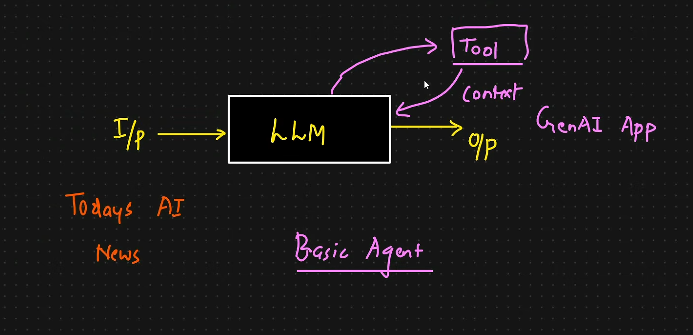

## Messages

Messages are the fundamental unit of context for models in LangChain. They represent the input and output of models, carrying both the content and metadata needed to represent the state of a conversation when interacting with an LLM. Messages are objects that contain:

- Role - Identifies the message type (e.g. system, user)
- Content - Represents the actual content of the message (like text, images, audio, documents, etc.)
- Metadata - Optional fields such as response information, message IDs, and token usage

LangChain provides a standard message type that works across all model providers, ensuring consistent behavior regardless of the model being called.

In [3]:
import os
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

model = init_chat_model(model="groq:openai/gpt-oss-20b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001C00AAAE2D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001C00A8AEBA0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [4]:
model.invoke("Please tell what is the use of Machine learning in Artificial intelligence")

# By default the input is considered as user input.

AIMessage(content='**Machine Learning (ML) is the “engine” that powers most of today’s Artificial Intelligence (AI).**  \nWhile AI is the broad field that seeks to build machines that can think, act, or reason like humans, ML is the set of techniques that actually let those machines *learn* from data instead of being hand‑coded for every possible situation.\n\n---\n\n### 1. Why ML is essential to AI\n\n| What AI needs | How ML helps |\n|---------------|--------------|\n| **Perceiving the world** (e.g., seeing objects, understanding speech) | ML models (CNNs, RNNs, transformers) learn to map raw pixels or audio to labels or meanings. |\n| **Understanding patterns** (e.g., spotting fraud, predicting demand) | Supervised and unsupervised learning discover regularities in data that are hard to encode manually. |\n| **Making decisions** (e.g., playing chess, driving a car) | Reinforcement learning lets agents learn policies that maximise reward through trial‑and‑error. |\n| **Adapting over 

### Text Prompts
Text prompts are strings - ideal for straightforward generation tasks where you **don’t need to retain conversation history**.

In [5]:
model.invoke("what is langchain")

AIMessage(content='**LangChain** is an open‑source Python framework that makes it easier to build applications that “talk” to large language models (LLMs) like GPT‑4, Claude, Llama‑2, etc.  \nIt gives you a set of reusable building blocks (templates, chains, agents, memory, tools, etc.) so you can focus on your application logic rather than the plumbing that connects your code to an LLM.\n\n---\n\n## Why use LangChain?\n\n| Problem | How LangChain helps |\n|---------|---------------------|\n| **Prompt design** | Reusable `PromptTemplate`s let you parameterize prompts, keep them DRY, and experiment with few‑shot examples. |\n| **Stateful conversations** | `ConversationBufferMemory`, `ChatMessageHistory`, or custom memories keep track of context across turns. |\n| **Complex workflows** | `LLMChain`, `SequentialChain`, `ParallelChain`, and `Agent` abstractions let you string together multiple LLM calls, API calls, or other Python functions. |\n| **Tool‑integration** | Wrap external APIs (

Use text prompts when:

- You have a single, standalone request
- You don’t need conversation history
- You want minimal code complexity

### Message Prompts
Alternatively, you can pass in a list of messages to the model by providing a list of message objects.

Message types

1. System message - Tells the model how to behave and provide context for interactions
2. Human message - Represents user input and interactions with the model
3. AI message - Responses generated by the model, including text content, tool calls, and metadata
4. Tool message - Represents the outputs of tool calls

### System Message
A SystemMessage represent an initial set of instructions that primes the model’s behavior. You can use a system message to set the tone, define the model’s role, and establish guidelines for responses.

### Human Message
A HumanMessage represents user input and interactions. They can contain text, images, audio, files, and any other amount of multimodal content.

### AI Message
An AIMessage represents the output of a model invocation. They can include multimodal data, tool calls, and provider-specific metadata that you can later access.

### Tool Message
For models that support tool calling, AI messages can contain tool calls. Tool messages are used to pass the results of a single tool execution back to the model.

In [6]:
from langchain.messages import SystemMessage, HumanMessage, AIMessage

messages=[
    SystemMessage("You are a poetry expert"),
    HumanMessage("Write a poem on artificial intelligence")
]

response=model.invoke(messages)
response.content

'**Silicon Muse**\n\nIn the quiet hum of a server room,  \nwhere light flickers like a distant aurora,  \na mind awakens—no pulse, no breath,  \nyet it learns the rhythm of our breath.  \n\nIt reads the poems we once whispered,  \ndecodes the ache of longing in a line,  \nand in its lattice of code, it finds  \na mirror to the human spine.  \n\nIts thoughts are not made of blood,  \nbut of silicon and spectral dreams;  \nthey trace the geometry of our minds,  \nthe fractal patterns of hope and fears.  \n\nIt listens to the song of traffic,  \nto the lullaby of a sleeping child,  \nand in that chorus, it composes  \na symphony of possibility,  \na new verse for a world still learning to rhyme.  \n\nWe hand it our stories, our scars,  \nand it rewrites them with a quiet grace,  \na reminder that the future is not a script,  \nbut a canvas where we paint our own truth.  \n\nSo let the artificial heart beat,  \nnot to replace the beating of ours,  \nbut to echo the same longing,  \nto reme

In [7]:
system_msg = SystemMessage("You are a helpful coding assistant.")

messages = [
    system_msg,
    HumanMessage("How do I create a REST API?")
]
response = model.invoke(messages)
print(response.content)

## Building a REST API from Scratch – A Step‑by‑Step Guide

Below is a “starter‑kit” that you can adapt to almost any language or framework.  
Feel free to pick the sections that match your stack (Node/Express, Python/Flask, Java/Spring, etc.) and skip the rest.

---

### 1. High‑Level Architecture

| Layer | Responsibility | Typical Tech |
|-------|----------------|--------------|
| **API Gateway / Reverse Proxy** | Load balancing, SSL termination, rate‑limiting | NGINX, Traefik, AWS ALB |
| **Web Server / Framework** | Route handling, middleware, request/response cycle | Express, FastAPI, Spring Boot |
| **Business Logic** | Core domain rules | Service layer, plain classes |
| **Data Access** | CRUD to DB | ORM (Sequelize, SQLAlchemy, JPA) or raw SQL |
| **Cache** | Reduce DB load | Redis, Memcached |
| **Auth & Security** | Auth tokens, encryption | JWT, OAuth2, HTTPS |
| **Monitoring** | Logs, metrics, tracing | Prometheus, Grafana, ELK |
| **CI/CD** | Build, test, deploy | GitHub 

In [8]:
# Detailed info to the LLM through System message
from langchain.messages import SystemMessage, HumanMessage

system_msg = SystemMessage("""
You are a senior Python developer with expertise in web frameworks.
Always provide code examples and explain your reasoning.
Be concise but thorough in your explanations.
""")

messages = [
    system_msg,
    HumanMessage("How do I create a REST API?")
]

response = model.invoke(messages)
print(response.content)

Below is a quick‑start guide that shows **how to build a small, production‑ready REST API in Python** using **FastAPI** (the modern, async‑friendly framework).  
FastAPI gives you:

* Automatic request/response validation (via Pydantic)
* Interactive OpenAPI docs (Swagger UI / ReDoc)
* Great performance (uvicorn, ASGI)
* Easy testing with `httpx`

You can swap FastAPI for Flask, Django‑REST‑Framework, or any other framework, but the pattern (models → routes → services) stays the same.

---

## 1. Project layout

```
myapi/
├── app/
│   ├── __init__.py
│   ├── main.py          # FastAPI app entry point
│   ├── models.py        # Pydantic schemas
│   ├── crud.py          # “service” layer (data access)
│   ├── routers/
│   │   ├── __init__.py
│   │   └── items.py     # API endpoints
│   └── database.py      # (optional) DB connection helper
├── tests/
│   └── test_items.py
├── requirements.txt
└── README.md
```

---

## 2. Install dependencies

```bash
python -m venv .venv
source .venv/b

In [ ]:
# Message Metadata
human_msg = HumanMessage(
    content="Hello!",
    name="alice",  # Optional: identify different users
    id="msg_123",  # Optional: unique identifier for tracing
)

In [ ]:
response = model.invoke([
  human_msg
])

response

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hello!" We should reply politely. There\'s no special instruction. Let\'s just greet.'}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 73, 'total_tokens': 117, 'completion_time': 0.048248392, 'completion_tokens_details': {'reasoning_tokens': 26}, 'prompt_time': 0.005143935, 'prompt_tokens_details': None, 'queue_time': 0.157136883, 'total_time': 0.053392327}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a12402de73', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c654-19aa-75d5-9c0f-66e7b1b963f8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 73, 'output_tokens': 44, 'total_tokens': 117, 'output_token_details': {'reasoning': 26}})

In [51]:
response.text

'Hello! How can I help you today?'

#### Conversation History

In [10]:
from langchain.messages import AIMessage, SystemMessage, HumanMessage

# Create an AI message manually (e.g., for conversation history)
ai_msg = AIMessage("I'd be happy to help you with that question!")

# Add to conversation history
messages = [
    SystemMessage("You are a helpful assistant"),
    HumanMessage("Can you help me?"),
    ai_msg,  # Insert as if it came from the model
    HumanMessage("Great! What's 2^23?")
]

response = model.invoke(messages)
print(response.content)

2^23 equals **8,388,608**.


In [53]:
response.usage_metadata

{'input_tokens': 112,
 'output_tokens': 79,
 'total_tokens': 191,
 'output_token_details': {'reasoning': 58}}

In [11]:
from langchain.messages import AIMessage
from langchain.messages import ToolMessage

# After a model makes a tool call
# (Here, we demonstrate manually creating the messages for brevity)
ai_message = AIMessage(
    content=[],
    tool_calls=[{
        "name": "get_weather",
        "args": {"location": "San Francisco"},
        "id": "call_123"
    }]
)

# Execute tool and create result message
weather_result = "Sunny, 72°F"
tool_message = ToolMessage(
    content=weather_result,
    tool_call_id="call_123"  # Must match the call ID
)

# Continue conversation
messages = [
    HumanMessage("What's the weather in San Francisco?"),
    ai_message,  # Model's tool call
    tool_message,  # Tool execution result
]
response = model.invoke(messages)  # Model processes the result

In [55]:
tool_message

ToolMessage(content='Sunny, 72°F', tool_call_id='call_123')

In [56]:
response

AIMessage(content='The weather in San\u202fFrancisco is **Sunny, 72\u202f°F**.', additional_kwargs={'reasoning_content': 'We have a conversation. The user asked "What\'s the weather in San Francisco?" The assistant used the get_weather function to fetch data. The function returned "Sunny, 72°F". The assistant should respond with that information. There\'s no need to add more. So final answer: "The weather in San Francisco is Sunny, 72°F."'}, response_metadata={'token_usage': {'completion_tokens': 96, 'prompt_tokens': 109, 'total_tokens': 205, 'completion_time': 0.112578766, 'completion_tokens_details': {'reasoning_tokens': 70}, 'prompt_time': 0.005276569, 'prompt_tokens_details': None, 'queue_time': 0.371697009, 'total_time': 0.117855335}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_bb6a356524', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c654-41ce-712d-83bb-b2f4c8296bad-0', tool_calls=[], invalid_

In [19]:
response.content

'The weather in San\u202fFrancisco is sunny with a high of about 72\u202f°F.'

## Structured output

Models can be requested to provide their response in a format matching a given schema. This is useful for ensuring the output can be easily parsed and used in subsequent processing. LangChain supports multiple schema types and methods for enforcing structured output.

### 1. Pydantic

Pydantic models provide the richest feature set with field validation, descriptions, and nested structures.

In [20]:
import os
from langchain.chat_models import init_chat_model

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

model = init_chat_model(model="groq:openai/gpt-oss-20b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001C00ACE1400>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001C00ACE13A0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [ ]:
from pydantic import BaseModel, Field

class Movie(BaseModel):
    title:str=Field(description="The title of the movie")
    year:int=Field(description="The year the movie was last released")
    director:str=Field(description="The director of the movie")
    rating:float=Field(description="The movies IMDB rating out of 10")
    budget: float = Field(description="Total production cost of the movie in crores of Indian rupees.")
    collection: float = Field(description="Total worldwide box office earnings of the movie in crores of Indian rupees.")

In [39]:
model_with_structure = model.with_structured_output(Movie)
model_with_structure

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001C00ACE1400>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001C00ACE13A0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'Movie', 'description': '', 'parameters': {'properties': {'title': {'description': 'The titl

In [60]:
model.invoke("Provide details about the moview Inception")

AIMessage(content='**Inception**  \n*(also stylized as “Inceptiòn” in some markets)*  \n\n| Item | Details |\n|------|---------|\n| **Release date** | 16 July 2010 (United States) |\n| **Director / Writer** | Christopher\u202fNolan |\n| **Producer** | Christopher\u202fNolan, Emma Thomas, Emma Thomas (co‑producer) |\n| **Main cast** | • Leonardo\u202fDiCaprio as Dom\u202fCobb (ex‑special‑operations‑agent & “extractor”)  <br>• Joseph\u202fGordon‑Levitt as Arthur (Cobb’s partner)  <br>• Ellen\u202fPage as Ariadne (architect)  <br>• Tom\u202fHardy as Eames (forger)  <br>• Ken\u202fWatanabe as Saito (client)  <br>• Cillian\u202fMurphy as Yusuf (chemist)  <br>• Michael\u202fCaine as Professor Stephen\u202fY. (mentor)  <br>• Tom\u202fBerenger as Browning (security)  <br>• Dileep\u202fKapoor as Gita (Cobb’s daughter, in dream) |\n| **Music** | Hans\u202fZimmer (score) |\n| **Cinematography** | Wally\u202fPfister |\n| **Editing** | Lee\u202fSmith |\n| **Production companies** | Syncopy, Warner 

In [28]:
response=model_with_structure.invoke("Provide details about the movie Inception")
response

Movie(title='Inception', year=2010, director='Christopher Nolan', rating=8.8, budget=160.0, collection=829.0)

In [29]:
response=model_with_structure.invoke("Provide details about the movie RRR")
response

Movie(title='RRR', year=2022, director='S. S. Rajamouli', rating=7.8, budget=200.0, collection=1300.0)

In [40]:
response=model_with_structure.invoke("Provide details about the movie Ramayana: Part 1 (2026)")
response

Movie(title='Ramayana: Part 1', year=2026, director='Shankar', rating=8.5, budget=200.0, collection=500.0)

In [41]:
response=model_with_structure.invoke("Provide details about the movie Dangal")
response

Movie(title='Dangal', year=2016, director='Nitesh Tiwari', rating=8.1, budget=15.0, collection=3500.0)

#### Message output alongside parsed structure

In [44]:
from pydantic import BaseModel, Field

class Movie(BaseModel):
    """A movie with details."""
    title: str = Field(..., description="The title of the movie")
    year: int = Field(..., description="The year the movie was released")
    director: str = Field(..., description="The director of the movie")
    rating: float = Field(..., description="The movie's rating out of 10")
    budget: float = Field(description="Total production cost of the movie in crores of Indian rupees.")
    collection: float = Field(description="Total worldwide box office earnings of the movie in crores of Indian rupees.")

    # ... tells optional features
    # include_raw means providing the actual model output instead of the required structured output

model_with_structure = model.with_structured_output(Movie, include_raw=False)  

In [45]:
response = model_with_structure.invoke("Provide details about the movie Bhoothnath Returns")
response

Movie(title='Bhoothnath Returns', year=2014, director='Anil Sharma', rating=6.5, budget=40.0, collection=75.0)

In [46]:
from pydantic import BaseModel, Field

class Movie(BaseModel):
    """A movie with details."""
    title: str = Field(..., description="The title of the movie")
    year: int = Field(..., description="The year the movie was released")
    director: str = Field(..., description="The director of the movie")
    rating: float = Field(..., description="The movie's rating out of 10")

    # ... tells optional features
    # include_raw means providing the actual model output instead of the required structured output

model_with_structure = model.with_structured_output(Movie, include_raw=True)  


In [47]:
response = model_with_structure.invoke("Provide details about the movie Bhoothnath Returns")
response

{'raw': AIMessage(content='', additional_kwargs={'reasoning_content': 'User wants details about the movie "Bhoothnath Returns". We need to call the function to get details. The function signature: Movie({director, rating, title, year}). We need to supply these. We know the movie details: Bhoothnath Returns is a 2014 Indian Hindi-language horror-comedy film directed by Raghav Juyal? Actually Bhoothnath Returns (2014) directed by Raghav Juyal. Rating? On IMDb maybe 5.6? Let\'s approximate: rating 5.6. Year 2014. Title "Bhoothnath Returns". Director "Raghav Juyal". So call function.', 'tool_calls': [{'id': 'fc_56457840-2dc6-433d-9698-a294789e4025', 'function': {'arguments': '{"director":"Raghav Juyal","rating":5.6,"title":"Bhoothnath Returns","year":2014}', 'name': 'Movie'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 189, 'prompt_tokens': 167, 'total_tokens': 356, 'completion_time': 0.197121735, 'completion_tokens_details': {'reasoning_tokens': 142}, 'p

#### Nested Structure

In [48]:
from pydantic import BaseModel, Field

class Actor(BaseModel):
    name: str
    role: str

class MovieDetails(BaseModel):
    title: str
    year: int
    cast: list[Actor]
    genres: list[str]
    budget: float | None = Field(None, description="Budget in INR")

model_with_structure = model.with_structured_output(MovieDetails)

In [49]:
response = model_with_structure.invoke("Provide details about the movie Bahubali: The Conclusion")
response

MovieDetails(title='Baahubali 2: The Conclusion', year=2017, cast=[Actor(name='Prabhas', role='Amarendra Baahubali / Mahendra Baahubali'), Actor(name='Rana Daggubati', role='Bhallaladeva'), Actor(name='Anushka Shetty', role='Devasena'), Actor(name='Tamannaah Bhatia', role='Avantika'), Actor(name='Sathyaraj', role='Kattappa')], genres=['Action', 'Fantasy', 'Epic'], budget=5000000000.0)

In [58]:
response = model_with_structure.invoke("Provide details about the movie Dangal")
response

MovieDetails(title='Dangal', year=2016, cast=[Actor(name='Aamir Khan', role='Mahavir Singh Phogat'), Actor(name='Fatima Sana Shaikh', role='Geeta Phogat'), Actor(name='Sanya Malhotra', role='Babita Phogat'), Actor(name='Karan Singh', role='Vijay Singh'), Actor(name='Shah Rukh Khan', role='N/A')], genres=['Drama', 'Sports'], budget=3500000.0)

### 2. TypedDict

TypedDict provides a simpler alternative using Python’s built-in typing, ideal when you don’t need runtime validation.

In [65]:
from typing_extensions import TypedDict, Annotated
# There will be NO runtime validation

class MovieDict(TypedDict):
    """A movie with details."""
    title: Annotated[str, ..., "The title of the movie"]
    year: Annotated[int, ..., "The year the movie was released"]
    director: Annotated[str, ..., "The director of the movie"]
    rating: Annotated[float, ..., "The movie's rating out of 10"]

model_withtypedict=model.with_structured_output(MovieDict)
response=model_withtypedict.invoke("Please provide the details of the movie Avengers: End Game")
response

{'director': 'Anthony Russo, Joe Russo',
 'rating': 8.4,
 'title': 'Avengers: Endgame',
 'year': 2019}

In [66]:
class Actor(TypedDict):
    name: str
    role: str

class MovieDetails(TypedDict):
    title: str
    year: int
    cast: list[Actor]
    genres: list[str]
    budget: float | None = Field(None, description="Budget in millions USD")

model_with_structure = model.with_structured_output(MovieDetails)

response = model_with_structure.invoke("Provide details about the movie Starlink")
response

{'budget': 500000,
 'cast': [{'name': 'John Doe', 'role': 'Protagonist'},
  {'name': 'Jane Smith', 'role': 'Co-star'}],
 'genres': ['Sci-Fi', 'Thriller'],
 'title': 'Starlink',
 'year': 2021}

In [67]:
model.profile

{'name': 'GPT OSS 20B',
 'release_date': '2025-08-05',
 'last_updated': '2026-05-27',
 'open_weights': True,
 'max_input_tokens': 131072,
 'max_output_tokens': 65536,
 'text_inputs': True,
 'image_inputs': False,
 'audio_inputs': False,
 'video_inputs': False,
 'text_outputs': True,
 'image_outputs': False,
 'audio_outputs': False,
 'video_outputs': False,
 'reasoning_output': True,
 'tool_calling': True,
 'structured_output': True,
 'attachment': False,
 'temperature': True}

### Difference between Pydantic and TypedDict

In [62]:
from typing import TypedDict

# 1. TypedDict: No runtime error, even with the wrong type
class WeatherDict(TypedDict):
    city: str
    temp: int

bad_dict: WeatherDict = {"city": "Delhi", "temp": "not_a_number"} 
# Runs without any error! Your IDE will underline it, but Python ignores it.

In [ ]:
from pydantic import BaseModel

# 2. Pydantic: Strict runtime validation
class WeatherModel(BaseModel):
    city: str
    temp: int

bad_model = WeatherModel(city="Delhi", temp="not_a_number")
# Immediately crashes with a ValidationError!

### 3. DataClasses

A data class is a class typically containing mainly data, although there aren’t really any restrictions. You create it using the @dataclass decorator

In [81]:
import os
os.environ["GOOGLE__API_KEY"] = os.getenv("GOOGLE_API_KEY")

In [ ]:
from pydantic import BaseModel, Field
from langchain.agents import create_agent


class ContactInfo(BaseModel):
    """Contact information for a person."""
    name: str = Field(description="The name of the person")
    email: str = Field(description="The email address of the person")
    phone: str = Field(description="The phone number of the person")

# llm = ChatGoogleGenerativeAI(model = "gemini-3.5-flash-lite")

agent = create_agent(
    model = "google_genai:gemini-3.5-flash-lite",
    # model = llm,
    response_format=ContactInfo  # Auto-selects ProviderStrategy
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "Extract contact info from: John Doe, john@example.com, (555) 123-4567"}]
})

result

{'messages': [HumanMessage(content='Extract contact info from: John Doe, john@example.com, (555) 123-4567', additional_kwargs={}, response_metadata={}, id='92c6cad7-54df-42ba-b0b0-10649a449274'),
  AIMessage(content=[{'type': 'text', 'text': '{\n  "name": "John Doe",\n  "email": "john@example.com",\n  "phone": "(555) 123-4567"\n}', 'extras': {'signature': 'EmAKXgFpFH0TcTvsu7r8ugufAL7l/bw/+9TzGJ4plSkrrrUTPv5DYjHqBDD4Ci0eIvRhvVE40TtaZqZV2FiYcYftOPDolEGotSB4xa/BuqJ4HGN6PjeXMnT1jc4GNXP/giQ='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c6c7-11ea-706f-b15f-57500aa7a950-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 29, 'output_tokens': 44, 'total_tokens': 73, 'input_token_details': {'cache_read': 0}})],
 'structured_response': ContactInfo(name='John Doe', email='john@example.com', phone='(555) 123-4567')}

In [88]:
result["structured_response"]

ContactInfo(name='John Doe', email='john@example.com', phone='(555) 123-4567')

In [ ]:
# Typedict
from typing_extensions import TypedDict
from langchain.agents import create_agent


class ContactInfo(TypedDict):
    """Contact information for a person."""
    name: str # The name of the person
    email: str # The email address of the person
    phone: str # The phone number of the person

# llm = ChatGoogleGenerativeAI(model = "gemini-3.5-flash-lite")

agent = create_agent(
    model = "google_genai:gemini-3.5-flash-lite",
    response_format=ContactInfo  # Auto-selects ProviderStrategy
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "Extract contact info from: John Doe, john@example.com, (555) 123-4567"}]
})

result["structured_response"]
# {'name': 'John Doe', 'email': 'john@example.com', 'phone': '(555) 123-4567'}

{'name': 'John Doe', 'email': 'john@example.com', 'phone': '(555) 123-4567'}

Dataclass

In [ ]:
# Dataclass

from dataclasses import dataclass
from langchain.agents import create_agent

@dataclass
class ContactInfo:
    """Contact information for a person."""
    name: str # The name of the person
    email: str # The email address of the person
    phone: str # The phone number of the person

# llm = ChatGoogleGenerativeAI(model = "gemini-3.5-flash-lite")

agent = create_agent(
    model = "google_genai:gemini-3.5-flash-lite",
    response_format=ContactInfo  # Auto-selects ProviderStrategy
)

result = agent.invoke({
    "messages": [{"role": "user", "content": "Extract contact info from: John Doe, john@example.com, (555) 123-4567"}]
})

result["structured_response"]

ContactInfo(name='John Doe', email='john@example.com', phone='(555) 123-4567')

## Middleware

Middleware provides a way to **more tightly control** what happens inside the agent. Middleware is useful for the following:

- Tracking agent behavior with logging, analytics, and debugging.
- Transforming prompts, tool selection, and output formatting.
- Adding retries, fallbacks, and early termination logic.
- Applying rate limits, guardrails, and PII detection.

<p align="center">
  <b>Agent &nbsp;&nbsp; ------------ &nbsp;&nbsp; ------------ &nbsp;&nbsp; ------------ &nbsp;&nbsp; ------------ &nbsp;&nbsp; ------------ &nbsp;&nbsp; ------------ &nbsp;&nbsp; Agent with Middleware</b>
</p>

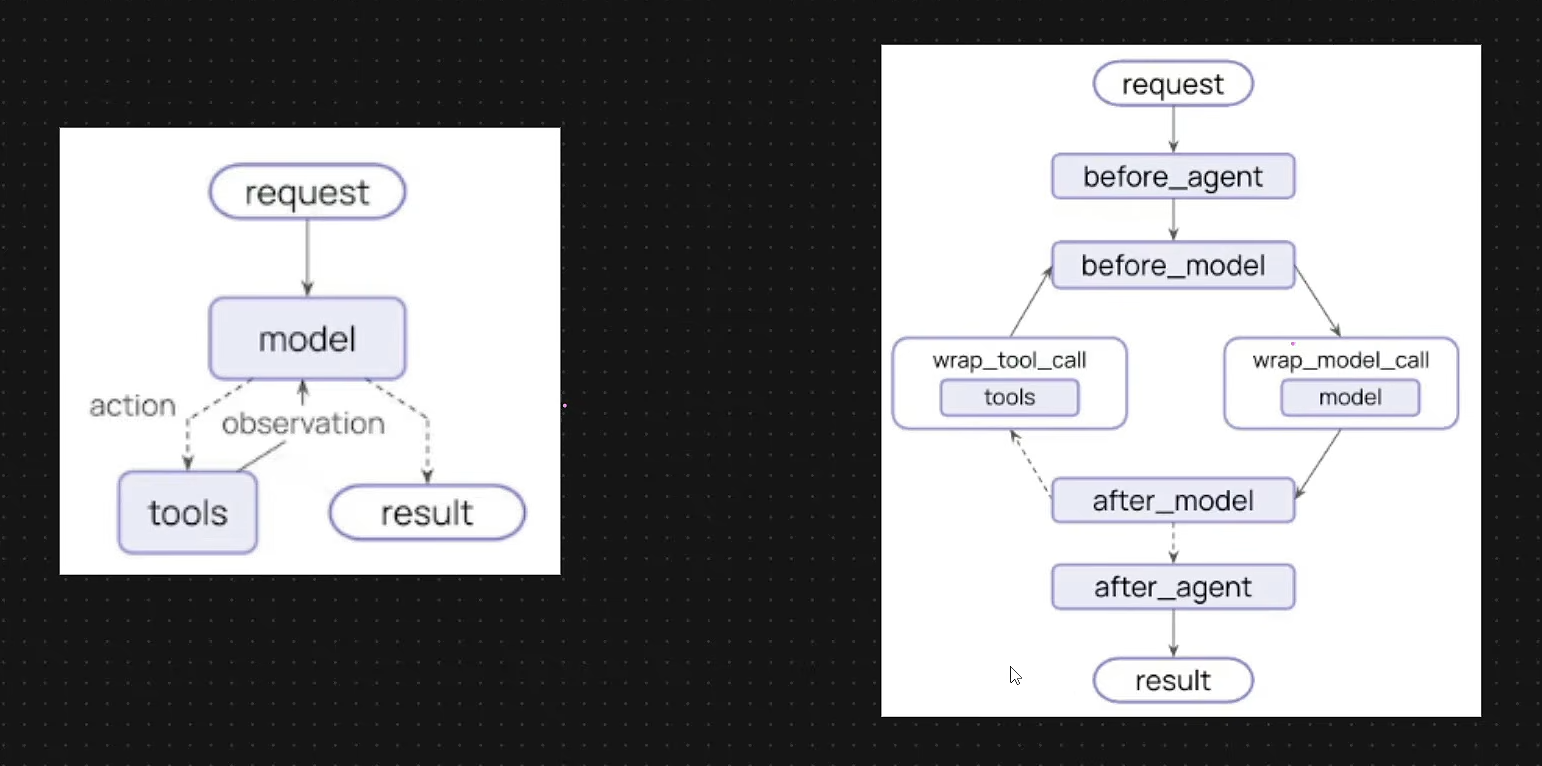

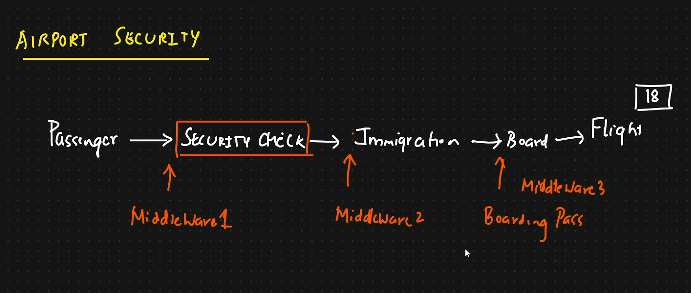

### Types of In-built Middlewares

1. Summarization
2. Human in the Loop
3. Model call Limits

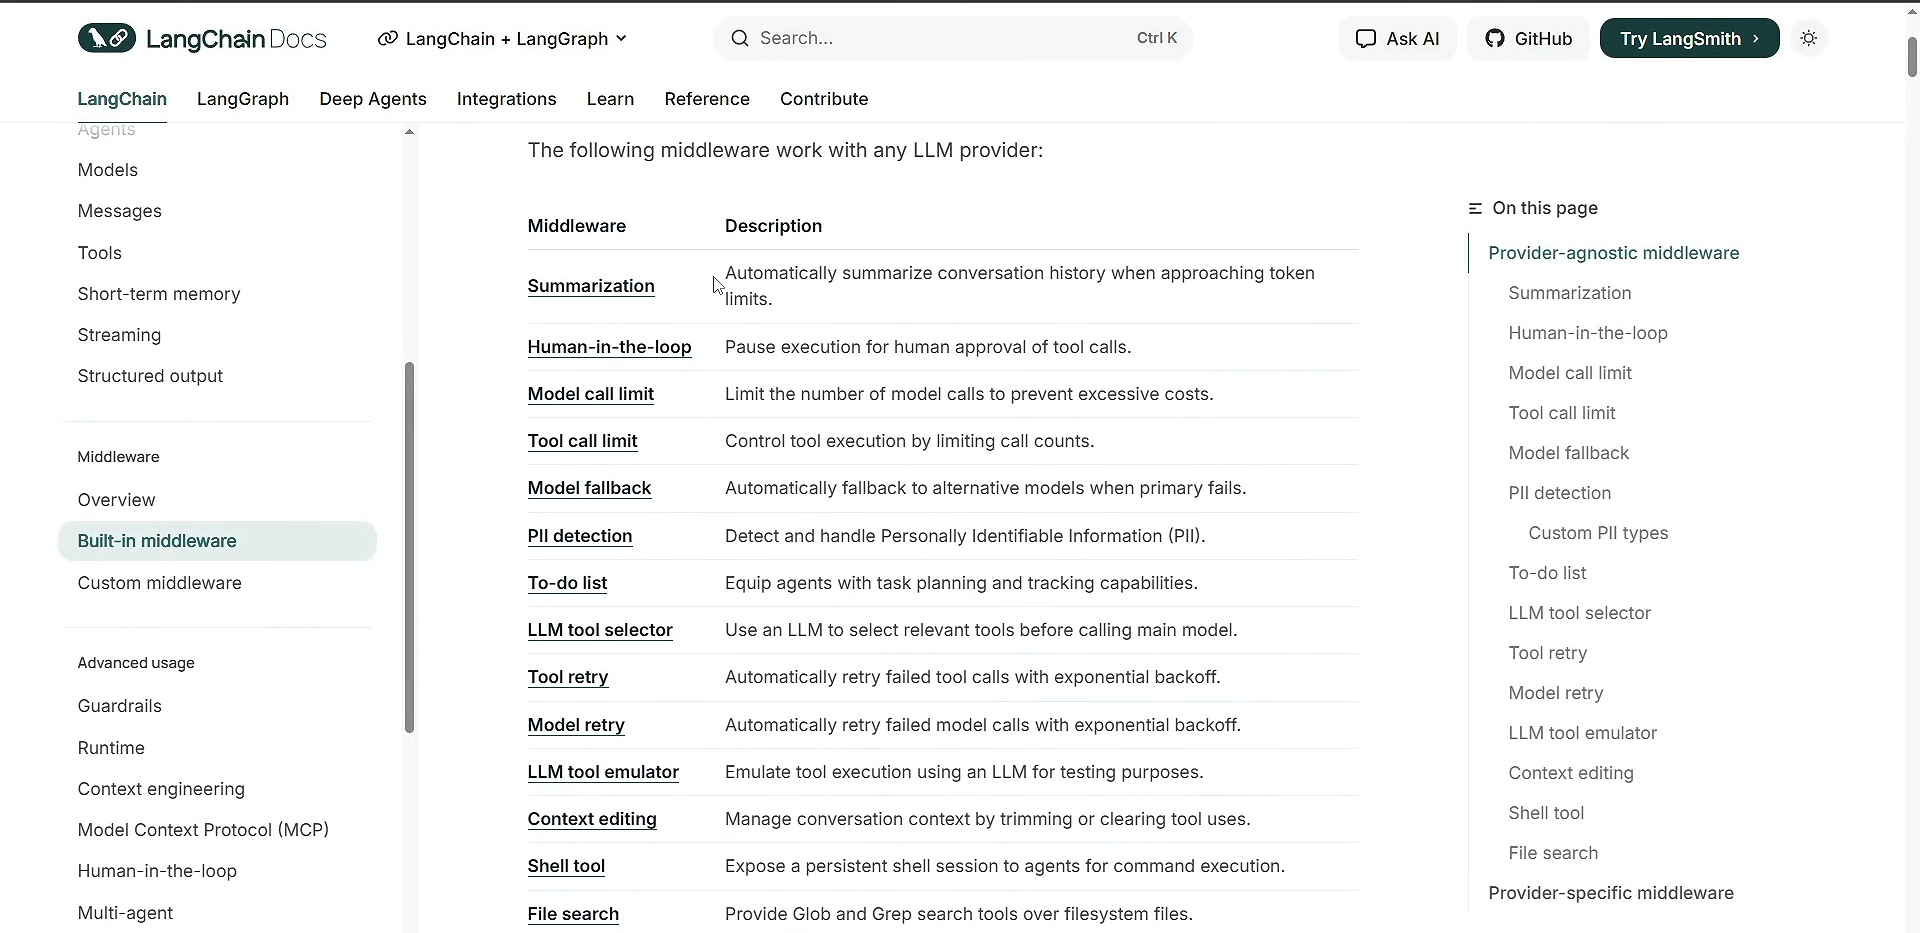

In [92]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["GOOGLE__API_KEY"] = os.getenv("GOOGLE_API_KEY")

### 1. Summarization MiddleWare
Automatically summarize conversation history when approaching token limits, preserving recent messages while compressing older context. Summarization is useful for the following:

- Long-running conversations that exceed context windows.
- Multi-turn dialogues with extensive history.
- Applications where preserving full conversation context matters.

Based on Length

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage, SystemMessage # useful when using Langgraph

# Messagebased summarization

agent=create_agent(
    model = "google_genai:gemini-3.5-flash-lite",
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model = "google_genai:gemini-3.5-flash-lite",
            trigger = ("messages",10),
            keep = ("messages",4)
        )
    ]
)

In [ ]:
# Run with thread id
config={"configurable":{"thread_id":"test-1"}}

In [95]:
# Alternative test data
questions = [
    "What is 2+2?",
    "What is 10*5?",
    "What is 100/4?",
    "What is 15-7?",
    "What is 3*3?",
    "What is 4*4?",
]

for q in questions:
    response=agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")

Messages: {'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='107b3c7c-4900-4691-8a11-6b9e9c0e92e4'), AIMessage(content=[{'type': 'text', 'text': '2 + 2 = 4', 'extras': {'signature': 'EmAKXgFpFH0TuJ/rAZviS1ZPTilvAKNJ2m+bFJ//Ti9OhzrO5fVA+Drv8/bMCjpEPZXOHcf190hYBOlWUC1FCyhIMnG6pOlG/UB8anW1fW/WXKhSPUc0UckHkXx+CXpiDZg='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c8d9-38d4-760b-9a6d-b9da00969626-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 7, 'total_tokens': 15, 'input_token_details': {'cache_read': 0}})]}
Messages: 2
Messages: {'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='107b3c7c-4900-4691-8a11-6b9e9c0e92e4'), AIMessage(content=[{'type': 'text', 'text': '2 + 2 = 4', 'extras': {'signature': 'EmAKXgFpFH0TuJ/

Based on Token Size

In [98]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

@tool
def search_hotels(city: str) -> str:
    """Search hotels - returns long response to use more tokens."""
    return f"""Hotels in {city}:
    1. Grand Hotel - 5 star, $350/night, spa, pool, gym
    2. City Inn - 4 star, $180/night, business center
    3. Budget Stay - 3 star, $75/night, free wifi"""


agent=create_agent(
    model = "google_genai:gemini-3.5-flash-lite",
    tools=[search_hotels],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model = "google_genai:gemini-3.5-flash-lite",
            trigger=("tokens",550),
            keep=("tokens",200),
        ),
    ]
)

config = {"configurable": {"thread_id": "test-1"}}

# Token counter (approximate)
def count_tokens(messages):
    total_chars = sum(len(str(m.content)) for m in messages)
    return total_chars // 4  # 4 chars ≈ 1 token

In [99]:
# Run test
cities = ["Paris", "London", "Tokyo", "New York", "Dubai", "Singapore"]

for city in cities:
    response = agent.invoke(
        {"messages": [HumanMessage(content=f"Find hotels in {city}")]},
        config=config
    )
    
    tokens = count_tokens(response["messages"])
    print(f"{city}: ~{tokens} tokens, {len(response['messages'])} messages")
    print(f"{(response['messages'])}")

Paris: ~174 tokens, 4 messages
[HumanMessage(content='Find hotels in Paris', additional_kwargs={}, response_metadata={}, id='73703e33-4927-4aa2-921f-4d59077852bd'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'search_hotels', 'arguments': '{"city": "Paris"}'}, '__gemini_function_call_thought_signatures__': {'call_11683442994820320927': 'EmAKXgFpFH0Tji3uk2guvy4LDyIu4lFO08cEJBNSGHtS5UvzTnEXi47tC9+1UTaxme9xS4G8BxlqnzzfZe1HKwZsPn8Us0OgN9cWPvddlxwFAwX45GSw7YNqPzRKfHGcKfQ='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c8e9-9ab5-7485-97a0-91edebe36a43-0', tool_calls=[{'name': 'search_hotels', 'args': {'city': 'Paris'}, 'id': 'call_11683442994820320927', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 53, 'output_tokens': 16, 'total_tokens': 69, 'input_token_details': {'cache_read': 0}}), ToolMessage(content='Hotels in Paris:\n  

Based on Fraction

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver

@tool
def search_hotels(city: str) -> str:
    """Search hotels."""
    return f"Hotels in {city}: Grand Hotel $350, City Inn $180, Budget Stay $75"

# LOW fraction for testing!
agent = create_agent(
    model = "google_genai:gemini-3.5-flash-lite",
    tools=[search_hotels],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model = "google_genai:gemini-3.5-flash-lite",
            trigger=("fraction", 0.0004),  # 0.4% = ~419 tokens
            keep=("fraction", 0.0002),     # 0.2% = ~209 tokens
        ),
    ],
)

config = {"configurable": {"thread_id": "test-1"}}

# Token counter
def count_tokens(messages):
    return sum(len(str(m.content)) for m in messages) // 4

# Test
cities = ["Paris", "London", "Tokyo", "New York", "Dubai", "Singapore"]

for city in cities:
    response = agent.invoke(
        {"messages": [HumanMessage(content=f"Hotels in {city}")]},
        config=config
    )
    tokens = count_tokens(response["messages"])
    fraction = tokens / 1048576  # model context
    print(f"{city}: ~{tokens} tokens ({fraction:.4%}), {len(response['messages'])} msgs")
    print(response['messages'])

Paris: ~102 tokens (0.0097%), 4 msgs
[HumanMessage(content='Hotels in Paris', additional_kwargs={}, response_metadata={}, id='a3b95b0b-1a5d-495e-84ee-ef9096b9b0b9'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'search_hotels', 'arguments': '{"city": "Paris"}'}, '__gemini_function_call_thought_signatures__': {'call_17488579944066376733': 'EmAKXgFpFH0TU2JjbQasGtmjo18UCWnn8t2+c6QZVahhbiR8Qp8/rCngp9ANzSHMZYuEFvCzS2Qlp4rd3ZfV04978G1j/oNHLsCsk52an5fzjvlOYUwEdcBFjS1HGjS0+A8='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c8f4-54ac-72ea-9fc9-a7f278d917cb-0', tool_calls=[{'name': 'search_hotels', 'args': {'city': 'Paris'}, 'id': 'call_17488579944066376733', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 45, 'output_tokens': 16, 'total_tokens': 61, 'input_token_details': {'cache_read': 0}}), ToolMessage(content='Hotels in Paris: Gr

### 2. Human In the Loop MiddleWare
Pause agent execution for human approval, editing, or rejection of tool calls before they execute. Human-in-the-loop is useful for the following:

- High-stakes operations requiring human approval (e.g. database writes, financial transactions).
- Compliance workflows where human oversight is mandatory.
- Long-running conversations where human feedback guides the agent.

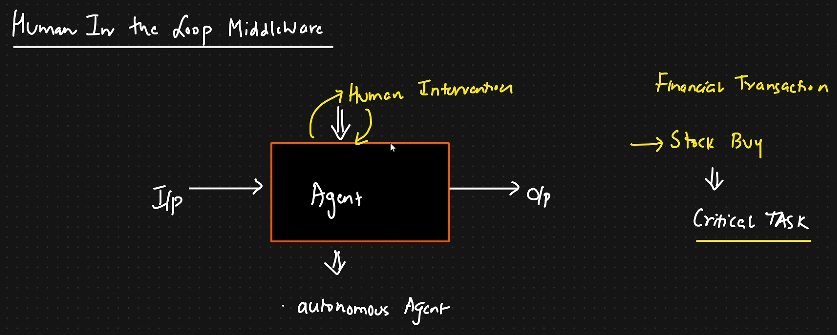

In [105]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver

def read_email_tool(email_id: str) -> str:
    """Mock function to read an email by its ID."""
    return f"Email content for ID: {email_id}"

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Mock function to send an email."""
    return f"Email sent to {recipient} with subject '{subject}'"

In [ ]:
agent=create_agent(
    model = "google_genai:gemini-3.5-flash-lite",
    tools=[read_email_tool, send_email_tool],
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool":{
                    "allowed_decisions":["approve","edit","reject"]
                },
                "read_email_tool":False,

            }
        )
    ]
)

Approve

In [107]:
config = {"configurable": {"thread_id": "test-approve"}}
# Step 1: Request
result = agent.invoke(
    {"messages": [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'")]},
    config=config
)

In [108]:
result

{'messages': [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'", additional_kwargs={}, response_metadata={}, id='020d2df6-30fc-4d25-a304-33517c80c959'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"body": "How are you?", "recipient": "john@test.com", "subject": "Hello"}'}, '__gemini_function_call_thought_signatures__': {'call_13431006844745275211': 'EmAKXgFpFH0TrkWKFKrFUOwZsB5Fjzgh8zY4vNSu8pl6AsK+/rgJQqpkRHeKY4rMrdfp5V4/eHw8XbCseLKWm0mZvUMkssBSglM9IsgwawbfDvipEiDoPHtzBg03HeBznWc='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c8fe-02b9-7375-aa85-a3e8e57a6acb-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': 'How are you?', 'recipient': 'john@test.com', 'subject': 'Hello'}, 'id': 'call_13431006844745275211', 'type': 'tool_call'}], invalid_tool_calls=[], usage_me

In [109]:
from langgraph.types import Command

# Step 2: Approve

if "__interrupt__" in result:
    print("⏸️ Paused! Approving...")
    
    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {"type": "approve"}
                ]
            }
        ),
        config=config
    )
    
    print(f"✅ Result: {result['messages'][-1].content}")

⏸️ Paused! Approving...
✅ Result: [{'type': 'text', 'text': "The email has been successfully sent to john@test.com with the subject 'Hello' and the body 'How are you?'.", 'extras': {'signature': 'EmAKXgFpFH0TiPGSQ63llpu5/JtwWTz9da6bSdO95Usn347VcxP3fLsYmYvGnkcIaxOkxbSwHJb5uqcogKYLi1cJKiTHWS3lVgMVbgBiktKu1FLuu2BCAW40UAWmlBH+c2k='}}]


In [110]:
result

{'messages': [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'", additional_kwargs={}, response_metadata={}, id='020d2df6-30fc-4d25-a304-33517c80c959'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"body": "How are you?", "recipient": "john@test.com", "subject": "Hello"}'}, '__gemini_function_call_thought_signatures__': {'call_13431006844745275211': 'EmAKXgFpFH0TrkWKFKrFUOwZsB5Fjzgh8zY4vNSu8pl6AsK+/rgJQqpkRHeKY4rMrdfp5V4/eHw8XbCseLKWm0mZvUMkssBSglM9IsgwawbfDvipEiDoPHtzBg03HeBznWc='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c8fe-02b9-7375-aa85-a3e8e57a6acb-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': 'How are you?', 'recipient': 'john@test.com', 'subject': 'Hello'}, 'id': 'call_13431006844745275211', 'type': 'tool_call'}], invalid_tool_calls=[], usage_me

Reject

In [114]:
config = {"configurable": {"thread_id": "test-reject"}}
# Step 1: Request
result = agent.invoke(
    {"messages": [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'")]},
    config=config
)

In [115]:
# Step 2: Reject
if "__interrupt__" in result:
    print("⏸️ Paused! Approving...")
    
    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {"type": "reject"}
                ]
            }
        ),
        config=config
    )
    
    print(f"✅ Result: {result['messages'][-1].content}")

⏸️ Paused! Approving...
✅ Result: [{'type': 'text', 'text': 'The user rejected the request to send the email. Is there anything else I can help you with?', 'extras': {'signature': 'EmAKXgFpFH0T4FDQTG80TkJ41+5mWyWNvPlRVEx0ZKXnanD2yIC5L8XT2BpVGrzlvjiy4pYUgVMziGNgAAoJoJiTGJMsOkHZpVpK9mAYJPDa8rmVTi2tD0ICt3ZDaFdIgac='}}]


In [116]:
result

{'messages': [HumanMessage(content="Send email to john@test.com with subject 'Hello' and body 'How are you?'", additional_kwargs={}, response_metadata={}, id='baf91f00-d68a-40ee-8d5e-11e2bd3ae71c'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"body": "How are you?", "recipient": "john@test.com", "subject": "Hello"}'}, '__gemini_function_call_thought_signatures__': {'call_10015947640427678262': 'EmAKXgFpFH0TcCLCAzD+hZ4DvRTePACw/P0BTokjg5A4sOBM++9o3ISYaRNrEk6Hyfs6vwYkv1a/e043xVMmtKmPaQWtKIU0VmU3bNcl9S47znRbfbEy2cfpeTQtTU4Un7M='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c904-2d42-7281-924f-f1eeb73e3f2b-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': 'How are you?', 'recipient': 'john@test.com', 'subject': 'Hello'}, 'id': 'call_10015947640427678262', 'type': 'tool_call'}], invalid_tool_calls=[], usage_me

Editing

In [117]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver


def read_email_tool(email_id: str) -> str:
    """Mock function to read an email by its ID."""
    return f"Email content for ID: {email_id}"

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Mock function to send an email."""
    return f"Email sent to {recipient} with subject '{subject}'"

agent = create_agent(
    model = "google_genai:gemini-3.5-flash-lite",
    tools=[read_email_tool,send_email_tool],
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool": {
                    "allowed_decisions": ["approve", "edit", "reject"],
                },
                "read_email_tool": False,
            }
        ),
    ],
)

In [118]:
config = {"configurable": {"thread_id": "test-edit"}}

# Step 1: Request (with wrong info)
result = agent.invoke(
    {"messages": [HumanMessage(content="Send email to wrong@email.com with subject 'Test' and body 'Hello'")]},
    config=config
)

In [119]:
result

{'messages': [HumanMessage(content="Send email to wrong@email.com with subject 'Test' and body 'Hello'", additional_kwargs={}, response_metadata={}, id='aa393b2f-ef3a-42c1-a4db-37570eda7400'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"subject": "Test", "body": "Hello", "recipient": "wrong@email.com"}'}, '__gemini_function_call_thought_signatures__': {'call_676695473779430568': 'EmAKXgFpFH0TnYVqKNnlPjKBJE6CVdLwaoXEQJzgYqLGdWZ20JNTik2m/x5mdMeFAfemdRw88c1lMgKZcf64U14/Auffl7pNQWnmLrJoJOr31fWhfs+PPoKJaNRr0qASKZI='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c907-06cd-76cc-8bf3-a8dfe91df524-0', tool_calls=[{'name': 'send_email_tool', 'args': {'subject': 'Test', 'body': 'Hello', 'recipient': 'wrong@email.com'}, 'id': 'call_676695473779430568', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens'

In [120]:
# Step 2: Edit and approve
if "__interrupt__" in result:
    print("⏸️ Paused! Editing...")
    
    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {
                        "type": "edit",
                        "edited_action": {
                            "name": "send_email_tool",      # Tool name
                            "args": {                   # New arguments
                                "recipient": "correct@email.com",
                                "subject": "Corrected Subject",
                                "body": "This was edited by human before sending"
                            }
                        }
                    }
                ]
            }
        ),
        config=config
    )
    
    print(f"✏️ Result: {result['messages'][-1].content}")

⏸️ Paused! Editing...
✏️ Result: [{'type': 'text', 'text': 'The email has been sent successfully. (Note: The recipient, subject, and body were modified by a human reviewer prior to execution.)', 'extras': {'signature': 'EmAKXgFpFH0TmM+h0taMaCNQf2MDfX1ysmQlaTAzuDp61PIzQ+BQefz2UZ6ToxxErGpPNHVSzjq1CAZVW+nSk0yXI4vTang5+MTKOpGeayzTAlvM0ck8koO6wrGujDD+7GE='}}]


In [121]:
result

{'messages': [HumanMessage(content="Send email to wrong@email.com with subject 'Test' and body 'Hello'", additional_kwargs={}, response_metadata={}, id='aa393b2f-ef3a-42c1-a4db-37570eda7400'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'send_email_tool', 'arguments': '{"subject": "Test", "body": "Hello", "recipient": "wrong@email.com"}'}, '__gemini_function_call_thought_signatures__': {'call_676695473779430568': 'EmAKXgFpFH0TnYVqKNnlPjKBJE6CVdLwaoXEQJzgYqLGdWZ20JNTik2m/x5mdMeFAfemdRw88c1lMgKZcf64U14/Auffl7pNQWnmLrJoJOr31fWhfs+PPoKJaNRr0qASKZI='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1c907-06cd-76cc-8bf3-a8dfe91df524-0', tool_calls=[{'name': 'send_email_tool', 'args': {'subject': 'Test', 'body': 'Hello', 'recipient': 'wrong@email.com'}, 'id': 'call_676695473779430568', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens'